In [1]:
from google.colab import files
arquivo = files.upload()

Saving idade_media_casamento.csv to idade_media_casamento.csv


In [4]:
import pandas as pd

df = pd.read_csv("idade_media_casamento.csv", sep=";", decimal=",", encoding="latin-1")
print(df.columns)
df.head(10)

Index(['ano', 'nome_ra', 'sexo_conjuge', 'cas_homoafetivo', 'idade_media'], dtype='object')


,ano,nome_ra,sexo_conjuge,cas_homoafetivo,idade_media
0,2013,Estado São Paulo,Homens,não,32.70
1,2013,Estado São Paulo,Homens,sim,38.12
2,2013,Estado São Paulo,Mulheres,não,29.89
3,2013,Estado São Paulo,Mulheres,sim,35.76
4,2013,RA Araçatuba,Homens,não,32.76
5,2013,RA Araçatuba,Homens,sim,43.54
6,2013,RA Araçatuba,Mulheres,não,30.03
7,2013,RA Araçatuba,Mulheres,sim,36.63
8,2013,RA Barretos,Homens,não,32.14
9,2013,RA Barretos,Homens,sim,48.83


In [5]:
# Só casamentos entre homem e mulher (cas_homoafetivo = "não"),
# senão "Homens" e "Mulheres" não formam casais comparáveis
d = df[df["cas_homoafetivo"] == "não"]

# Tira a linha do total do Estado, para não repetir informação das regiões
d = d[d["nome_ra"] != "Estado São Paulo"]

# Coloca Homens e Mulheres em colunas lado a lado
tabela = d.pivot_table(index=["ano", "nome_ra"],
                       columns="sexo_conjuge",
                       values="idade_media").reset_index()

tabela = tabela.dropna(subset=["Homens", "Mulheres"])
print(len(tabela), "linhas")
tabela.head()

208 linhas


sexo_conjuge,ano,nome_ra,Homens,Mulheres
0,2013,RA Araçatuba,32.76,30.03
1,2013,RA Barretos,32.14,29.34
2,2013,RA Bauru,32.59,29.85
3,2013,RA Campinas,32.27,29.52
4,2013,RA Central,32.79,30.00


Inclinação (a): 1.0305
Intercepto (b): -3.7899
R²: 0.9382
Equação: y = 1.0305·x + -3.7899


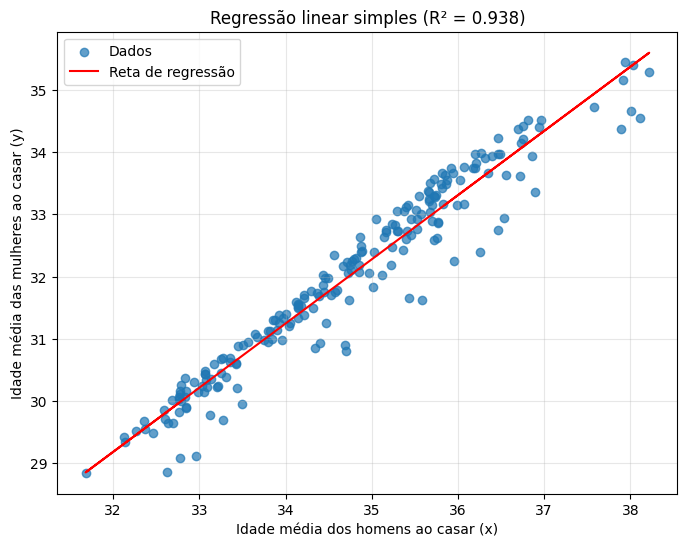

In [6]:
import matplotlib.pyplot as plt
from scipy import stats

x = tabela["Homens"]      # idade média dos homens ao casar
y = tabela["Mulheres"]    # idade média das mulheres ao casar

res = stats.linregress(x, y)

print("Inclinação (a):", round(res.slope, 4))
print("Intercepto (b):", round(res.intercept, 4))
print("R²:", round(res.rvalue**2, 4))
print(f"Equação: y = {res.slope:.4f}·x + {res.intercept:.4f}")

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, label="Dados")
plt.plot(x, res.intercept + res.slope * x, color="red", label="Reta de regressão")
plt.xlabel("Idade média dos homens ao casar (x)")
plt.ylabel("Idade média das mulheres ao casar (y)")
plt.title(f"Regressão linear simples (R² = {res.rvalue**2:.3f})")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("dispersao.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
from google.colab import files
files.download("dispersao.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>